Import libraries and load datasets



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your existing CSV files
accidents = pd.read_csv("accidents.csv")
roads = pd.read_csv("roads.csv")
traffic = pd.read_csv("traffic.csv")
vehicles = pd.read_csv("vehicles.csv")
weather = pd.read_csv("weather.csv")

print("All datasets loaded successfully!")
print("Accidents:", accidents.shape)
print("Roads:", roads.shape)
print("Traffic:", traffic.shape)
print("Vehicles:", vehicles.shape)
print("Weather:", weather.shape)

All datasets loaded successfully!
Accidents: (1500, 5)
Roads: (1500, 4)
Traffic: (1500, 3)
Vehicles: (2060, 3)
Weather: (1500, 4)


Explore the datasets

In [3]:
datasets = {
    "accidents": accidents,
    "roads": roads,
    "traffic": traffic,
    "vehicles": vehicles,
    "weather": weather
}

for name, df in datasets.items():
    print("\n---", name.upper(), "---")
    print("Rows and columns:", df.shape)
    print("Column names:", df.columns.tolist())
    print("\nData types:")
    print(df.dtypes)
    print("\nMissing values:")
    print(df.isnull().sum())
    print("Duplicate rows:", df.duplicated().sum())
    display(df.head())


--- ACCIDENTS ---
Rows and columns: (1500, 5)
Column names: ['incident_id', 'date', 'time', 'location', 'severity']

Data types:
incident_id    object
date           object
time            int64
location       object
severity       object
dtype: object

Missing values:
incident_id     0
date            0
time            0
location       11
severity        1
dtype: int64
Duplicate rows: 0


,incident_id,date,time,location,severity
0,INC-2024-0001,2024-01-01,12,Highland Road Junction,Major
1,INC-2024-0002,2024-01-01,18,Old Town Market Square,Fatal
2,INC-2024-0003,2024-01-01,0,City Center Ring Road,Minor
3,INC-2024-0004,2024-01-02,8,Airport Access Road,Minor
4,INC-2024-0005,2024-01-02,17,Main Street & 5th Ave,Major



--- ROADS ---
Rows and columns: (1500, 4)
Column names: ['incident_id', 'road_type', 'junction', 'speed_limit']

Data types:
incident_id    object
road_type      object
junction       object
speed_limit     int64
dtype: object

Missing values:
incident_id    0
road_type      0
junction       0
speed_limit    0
dtype: int64
Duplicate rows: 0


,incident_id,road_type,junction,speed_limit
0,INC-2024-0001,Highway,Roundabout,120
1,INC-2024-0002,Residential Road,T-Junction,30
2,INC-2024-0003,Rural Road,No Junction,80
3,INC-2024-0004,Urban Road,Crossroads,50
4,INC-2024-0005,Highway,Roundabout,120



--- TRAFFIC ---
Rows and columns: (1500, 3)
Column names: ['incident_id', 'traffic_volume', 'peak_flag']

Data types:
incident_id       object
traffic_volume    object
peak_flag         object
dtype: object

Missing values:
incident_id       0
traffic_volume    0
peak_flag         0
dtype: int64
Duplicate rows: 0


,incident_id,traffic_volume,peak_flag
0,INC-2024-0001,803,No
1,INC-2024-0002,"1,946",Yes
2,INC-2024-0003,391,No
3,INC-2024-0004,"2,442",Yes
4,INC-2024-0005,"2,515",Yes



--- VEHICLES ---
Rows and columns: (2060, 3)
Column names: ['incident_id', 'vehicle_category', 'vehicle_count']

Data types:
incident_id         object
vehicle_category    object
vehicle_count        int64
dtype: object

Missing values:
incident_id         0
vehicle_category    0
vehicle_count       0
dtype: int64
Duplicate rows: 88


,incident_id,vehicle_category,vehicle_count
0,INC-2024-0001,Car,1
1,INC-2024-0002,Car,1
2,INC-2024-0003,Bus,1
3,INC-2024-0003,Bicycle,1
4,INC-2024-0004,Truck,1



--- WEATHER ---
Rows and columns: (1500, 4)
Column names: ['incident_id', 'rain', 'visibility', 'weather_condition']

Data types:
incident_id          object
rain                 object
visibility           object
weather_condition    object
dtype: object

Missing values:
incident_id          0
rain                 9
visibility           8
weather_condition    9
dtype: int64
Duplicate rows: 0


,incident_id,rain,visibility,weather_condition
0,INC-2024-0001,No Rain,"10,000",Clear
1,INC-2024-0002,Heavy Rain,800,Stormy
2,INC-2024-0003,No Rain,400,Foggy
3,INC-2024-0004,No Rain,"7,500",Cloudy
4,INC-2024-0005,No Rain,"10,000",Clear


Check duplicate incident IDs

In [4]:
for name, df in datasets.items():
    if "incident_id" in df.columns:
        print(
            name,
            "- Duplicate incident IDs:",
            df["incident_id"].duplicated().sum()
        )

accidents - Duplicate incident IDs: 3
roads - Duplicate incident IDs: 3
traffic - Duplicate incident IDs: 3
vehicles - Duplicate incident IDs: 563
weather - Duplicate incident IDs: 3


Clean the datasets

In [5]:
# Create working copies
accidents = accidents.copy()
roads = roads.copy()
traffic = traffic.copy()
vehicles = vehicles.copy()
weather = weather.copy()

# Standardise incident IDs
for df in [accidents, roads, traffic, vehicles, weather]:
    df["incident_id"] = df["incident_id"].astype(str).str.strip()

# Remove exact duplicate rows
for df in [accidents, roads, traffic, vehicles, weather]:
    df.drop_duplicates(inplace=True)

# Clean accident locations
accidents["location"] = (
    accidents["location"].astype("string").str.strip()
)
accidents["location"] = accidents["location"].replace("", pd.NA)
accidents["location"] = accidents["location"].fillna("Unknown")

# Convert date
accidents["date"] = pd.to_datetime(
    accidents["date"], errors="coerce"
)

# Convert time to numeric
accidents["time"] = pd.to_numeric(
    accidents["time"], errors="coerce"
)

# Standardise severity categories
severity_map = {
    "fatal": "Fatal",
    "critical": "Fatal",
    "major": "Major",
    "moderate": "Major",
    "minor": "Minor",
    "minor injury": "Minor"
}

accidents["severity"] = (
    accidents["severity"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(severity_map)
    .fillna("Unknown")
)

# Standardise road and junction labels
roads["road_type"] = (
    roads["road_type"].astype("string").str.strip().str.title()
)
roads["junction"] = (
    roads["junction"].astype("string").str.strip()
)

# Clean traffic volume
traffic["traffic_volume"] = pd.to_numeric(
    traffic["traffic_volume"]
    .astype("string")
    .str.replace(",", "", regex=False),
    errors="coerce"
)

traffic["peak_flag"] = (
    traffic["peak_flag"].astype("string").str.strip().str.title()
)

# Clean weather
weather["rain"] = (
    weather["rain"].astype("string").str.strip().str.title()
)
weather["weather_condition"] = (
    weather["weather_condition"]
    .astype("string").str.strip().str.title()
)
weather["visibility"] = pd.to_numeric(
    weather["visibility"], errors="coerce"
)

# Convert numerical fields
roads["speed_limit"] = pd.to_numeric(
    roads["speed_limit"], errors="coerce"
)
vehicles["vehicle_count"] = pd.to_numeric(
    vehicles["vehicle_count"], errors="coerce"
)

vehicles["vehicle_category"] = (
    vehicles["vehicle_category"]
    .astype("string").str.strip().str.title()
)

print("Basic data cleaning completed.")

Basic data cleaning completed.


Remove repeated incident records

In [6]:
for name, df in [
    ("accidents", accidents),
    ("roads", roads),
    ("traffic", traffic),
    ("weather", weather)
]:
    before = len(df)

    df.drop_duplicates(
        subset="incident_id",
        keep="first",
        inplace=True
    )

    print(name, "- Removed records:", before - len(df))

accidents - Removed records: 3
roads - Removed records: 3
traffic - Removed records: 3
weather - Removed records: 3


Summarise vehicle records

In [7]:
vehicle_summary = vehicles.groupby("incident_id").agg(
    total_vehicle_count=("vehicle_count", "sum"),
    vehicle_categories=(
        "vehicle_category",
        lambda x: ", ".join(sorted(x.dropna().unique()))
    )
).reset_index()

display(vehicle_summary.head())

,incident_id,total_vehicle_count,vehicle_categories
0,INC-2024-0001,1,Car
1,INC-2024-0002,1,Car
2,INC-2024-0003,2,"Bicycle, Bus"
3,INC-2024-0004,1,Truck
4,INC-2024-0005,1,Auto Rickshaw


Merge the datasets

In [8]:
combined = accidents.merge(
    roads, on="incident_id", how="left",
    validate="one_to_one"
)

combined = combined.merge(
    weather, on="incident_id", how="left",
    validate="one_to_one"
)

combined = combined.merge(
    traffic, on="incident_id", how="left",
    validate="one_to_one"
)

combined = combined.merge(
    vehicle_summary, on="incident_id", how="left",
    validate="one_to_one"
)

print("Combined dataset:", combined.shape)
print("Unique incidents:", combined["incident_id"].nunique())

display(combined.head())

Combined dataset: (1497, 15)
Unique incidents: 1497


,incident_id,date,time,location,severity,road_type,junction,speed_limit,rain,visibility,weather_condition,traffic_volume,peak_flag,total_vehicle_count,vehicle_categories
0,INC-2024-0001,2024-01-01,12,Highland Road Junction,Major,Highway,Roundabout,120,No Rain,NaN,Clear,803,No,1,Car
1,INC-2024-0002,2024-01-01,18,Old Town Market Square,Fatal,Residential Road,T-Junction,30,Heavy Rain,800.0,Stormy,1946,Yes,1,Car
2,INC-2024-0003,2024-01-01,0,City Center Ring Road,Minor,Rural Road,No Junction,80,No Rain,400.0,Foggy,391,No,2,"Bicycle, Bus"
3,INC-2024-0004,2024-01-02,8,Airport Access Road,Minor,Urban Road,Crossroads,50,No Rain,NaN,Cloudy,2442,Yes,1,Truck
4,INC-2024-0005,2024-01-02,17,Main Street & 5th Ave,Major,Highway,Roundabout,120,No Rain,NaN,Clear,2515,Yes,1,Auto Rickshaw


Verify the cleaned dataset

In [9]:
print("Missing values:")
print(combined.isnull().sum())

print("\nDuplicate rows:", combined.duplicated().sum())

print("\nSeverity distribution:")
print(combined["severity"].value_counts(dropna=False))

print("\nRoad type distribution:")
print(combined["road_type"].value_counts(dropna=False))

Missing values:
incident_id               0
date                      0
time                      0
location                  0
severity                  0
road_type                 0
junction                  0
speed_limit               0
rain                      9
visibility             1198
weather_condition         8
traffic_volume            0
peak_flag                 0
total_vehicle_count       0
vehicle_categories        0
dtype: int64

Duplicate rows: 0

Severity distribution:
severity
Minor      895
Major      449
Fatal      151
Unknown      2
Name: count, dtype: int64

Road type distribution:
road_type
Highway             375
Rural Road          375
Residential Road    374
Urban Road          373
Name: count, dtype: Int64


Feature engineering

In [10]:
# Extract time-based features
combined["hour"] = combined["time"]

combined["day_of_week"] = combined["date"].dt.day_name()
combined["month"] = combined["date"].dt.month_name()

combined["is_weekend"] = (
    combined["date"].dt.dayofweek >= 5
)

def get_daypart(hour):
    if pd.isna(hour):
        return "Unknown"
    elif 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

combined["daypart"] = combined["hour"].apply(get_daypart)

# Fatal and Major are treated as severe
combined["is_severe"] = combined["severity"].map({
    "Fatal": 1,
    "Major": 1,
    "Minor": 0
})

display(combined.head())

,incident_id,date,time,location,severity,road_type,junction,speed_limit,rain,visibility,...,traffic_volume,peak_flag,total_vehicle_count,vehicle_categories,hour,day_of_week,month,is_weekend,daypart,is_severe
0,INC-2024-0001,2024-01-01,12,Highland Road Junction,Major,Highway,Roundabout,120,No Rain,NaN,...,803,No,1,Car,12,Monday,January,False,Afternoon,1.0
1,INC-2024-0002,2024-01-01,18,Old Town Market Square,Fatal,Residential Road,T-Junction,30,Heavy Rain,800.0,...,1946,Yes,1,Car,18,Monday,January,False,Evening,1.0
2,INC-2024-0003,2024-01-01,0,City Center Ring Road,Minor,Rural Road,No Junction,80,No Rain,400.0,...,391,No,2,"Bicycle, Bus",0,Monday,January,False,Night,0.0
3,INC-2024-0004,2024-01-02,8,Airport Access Road,Minor,Urban Road,Crossroads,50,No Rain,NaN,...,2442,Yes,1,Truck,8,Tuesday,January,False,Morning,0.0
4,INC-2024-0005,2024-01-02,17,Main Street & 5th Ave,Major,Highway,Roundabout,120,No Rain,NaN,...,2515,Yes,1,Auto Rickshaw,17,Tuesday,January,False,Evening,1.0


EDA — accident hotspots

,total_accidents,severe_accidents
location,,
Grand Avenue & 10th St,75,75.0
Harbor View Highway,75,75.0
Highland Road Junction,75,75.0
Riverfront Drive Corridor,74,74.0
Bay Bridge Approach,74,74.0
West Industrial Parkway,74,74.0
Old Town Market Square,73,73.0
Main Street & 5th Ave,72,72.0
Unknown,11,6.0


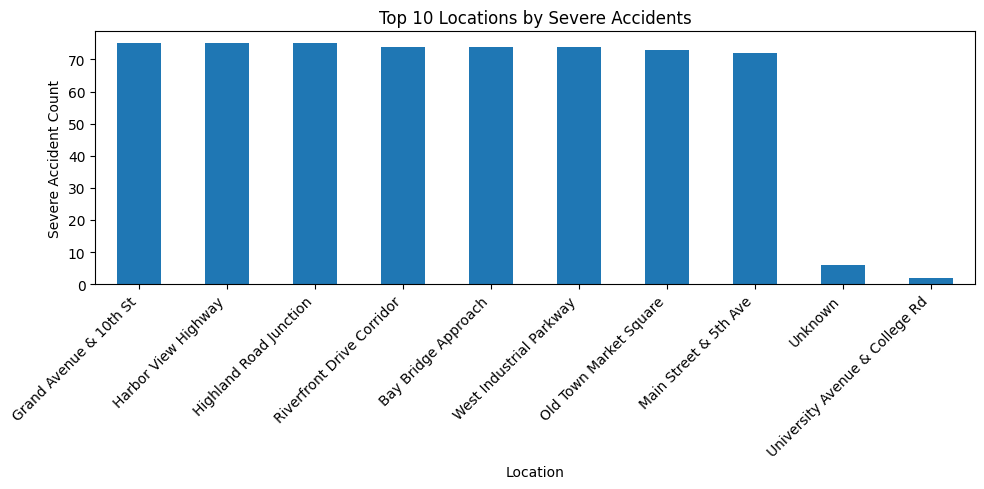

In [11]:
location_summary = combined.groupby("location").agg(
    total_accidents=("incident_id", "nunique"),
    severe_accidents=("is_severe", "sum")
).sort_values("severe_accidents", ascending=False)

display(location_summary.head(10))

location_summary["severe_accidents"].head(10).plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Top 10 Locations by Severe Accidents")
plt.xlabel("Location")
plt.ylabel("Severe Accident Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

EDA — time-of-day analysis

,accident_count
hour,
0,63
1,63
2,62
5,62
6,63
7,62
8,124
9,63
11,62


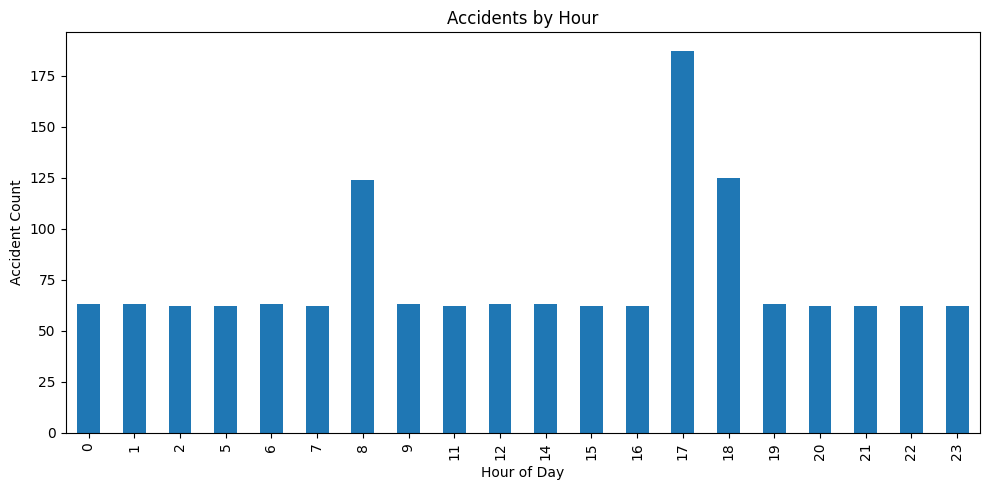

In [12]:
time_summary = combined.groupby("hour").agg(
    accident_count=("incident_id", "nunique")
).sort_index()

display(time_summary)

time_summary["accident_count"].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Accidents by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Accident Count")
plt.tight_layout()
plt.show()

EDA — weather and severity

,accident_count,severe_accidents,severe_rate
weather_condition,,,
Rainy,449,149.0,0.331849
Clear,445,300.0,0.677201
Cloudy,298,0.0,0.000000
Foggy,149,0.0,0.000000
Stormy,148,148.0,1.000000
<NA>,8,3.0,0.375000


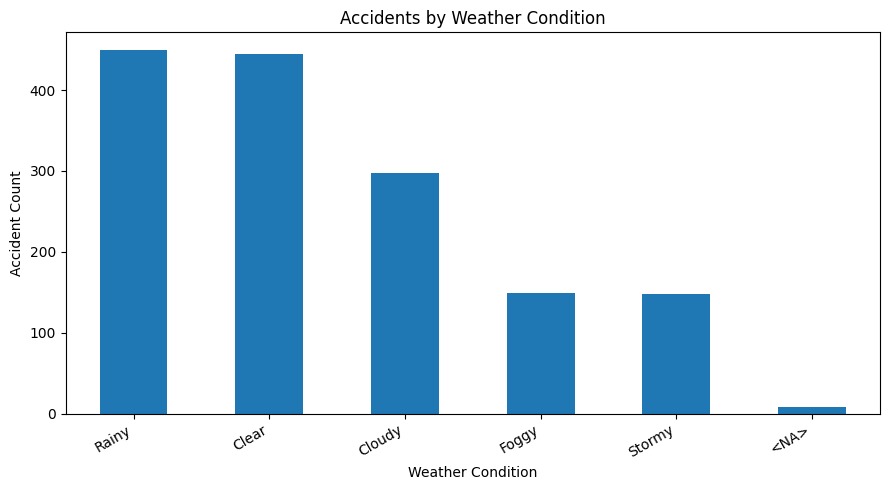

In [13]:
weather_summary = combined.groupby(
    "weather_condition", dropna=False
).agg(
    accident_count=("incident_id", "nunique"),
    severe_accidents=("is_severe", "sum"),
    severe_rate=("is_severe", "mean")
).sort_values("accident_count", ascending=False)

display(weather_summary)

weather_summary["accident_count"].plot(
    kind="bar", figsize=(9, 5)
)

plt.title("Accidents by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Accident Count")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

EDA — junction analysis

,accident_count,severe_accidents
junction,,
Crossroads,375,152.0
No Junction,375,150.0
T-Junction,374,149.0
Roundabout,373,149.0


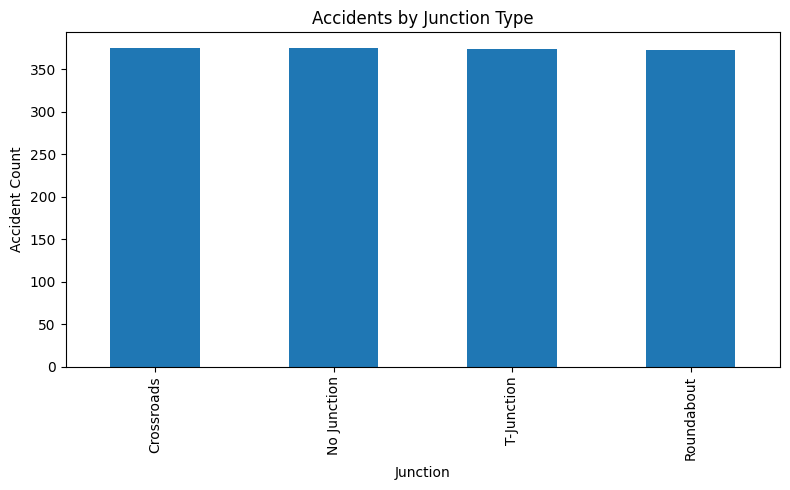

In [14]:
junction_summary = combined.groupby("junction").agg(
    accident_count=("incident_id", "nunique"),
    severe_accidents=("is_severe", "sum")
).sort_values("accident_count", ascending=False)

display(junction_summary)

junction_summary["accident_count"].plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Accidents by Junction Type")
plt.xlabel("Junction")
plt.ylabel("Accident Count")
plt.tight_layout()
plt.show()

EDA — traffic-volume analysis

,accident_count,severe_accidents
road_type,,
Highway,375,149.0
Rural Road,375,149.0
Residential Road,374,149.0
Urban Road,373,153.0


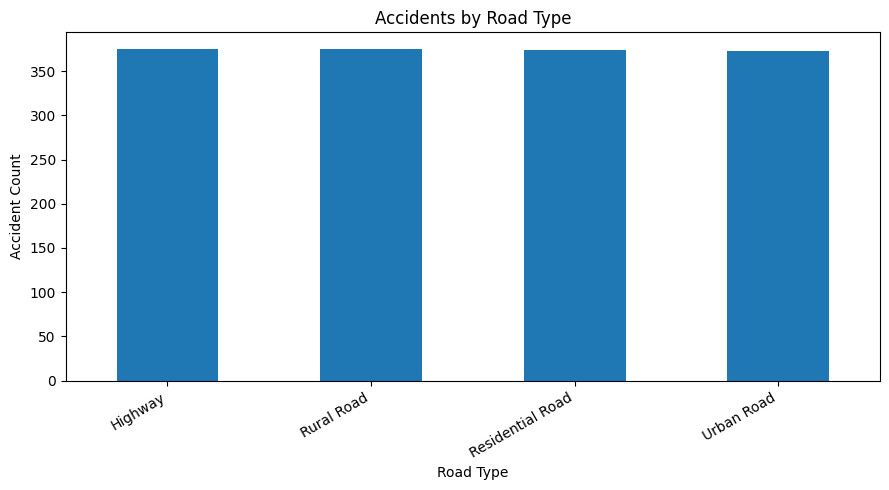

In [15]:
road_summary = combined.groupby("road_type").agg(
    accident_count=("incident_id", "nunique"),
    severe_accidents=("is_severe", "sum")
).sort_values("accident_count", ascending=False)

display(road_summary)

road_summary["accident_count"].plot(
    kind="bar", figsize=(9, 5)
)

plt.title("Accidents by Road Type")
plt.xlabel("Road Type")
plt.ylabel("Accident Count")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

EDA — traffic-volume analysis

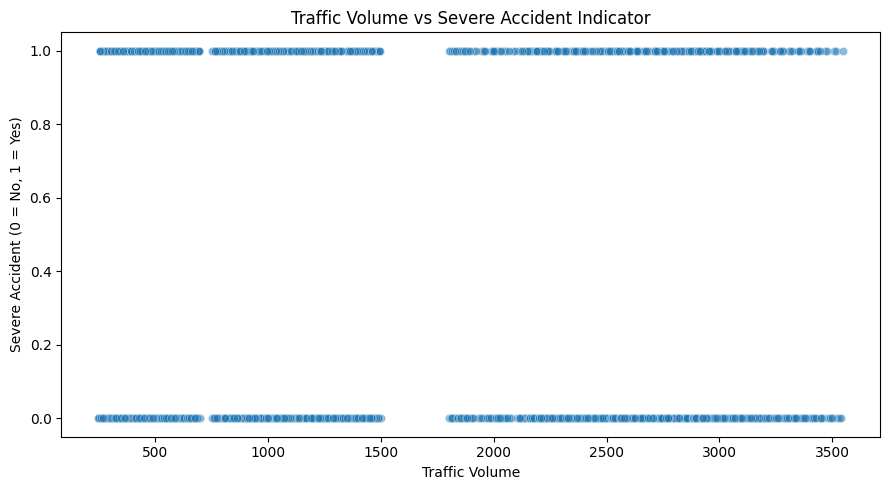

Correlation: -0.00017213503048645778


In [16]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=combined.dropna(
        subset=["traffic_volume", "is_severe"]
    ),
    x="traffic_volume",
    y="is_severe",
    alpha=0.5
)

plt.title("Traffic Volume vs Severe Accident Indicator")
plt.xlabel("Traffic Volume")
plt.ylabel("Severe Accident (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()

print(
    "Correlation:",
    combined["traffic_volume"].corr(combined["is_severe"])
)

Feature selection

In [17]:
selected_features = [
    "location",
    "hour",
    "day_of_week",
    "month",
    "daypart",
    "is_weekend",
    "road_type",
    "junction",
    "speed_limit",
    "rain",
    "visibility",
    "weather_condition",
    "traffic_volume",
    "peak_flag",
    "vehicle_categories",
    "total_vehicle_count",
    "severity",
    "is_severe"
]

feature_data = combined[selected_features].copy()

print("Selected feature columns:")
print(feature_data.columns.tolist())

display(feature_data.head())

Selected feature columns:
['location', 'hour', 'day_of_week', 'month', 'daypart', 'is_weekend', 'road_type', 'junction', 'speed_limit', 'rain', 'visibility', 'weather_condition', 'traffic_volume', 'peak_flag', 'vehicle_categories', 'total_vehicle_count', 'severity', 'is_severe']


,location,hour,day_of_week,month,daypart,is_weekend,road_type,junction,speed_limit,rain,visibility,weather_condition,traffic_volume,peak_flag,vehicle_categories,total_vehicle_count,severity,is_severe
0,Highland Road Junction,12,Monday,January,Afternoon,False,Highway,Roundabout,120,No Rain,NaN,Clear,803,No,Car,1,Major,1.0
1,Old Town Market Square,18,Monday,January,Evening,False,Residential Road,T-Junction,30,Heavy Rain,800.0,Stormy,1946,Yes,Car,1,Fatal,1.0
2,City Center Ring Road,0,Monday,January,Night,False,Rural Road,No Junction,80,No Rain,400.0,Foggy,391,No,"Bicycle, Bus",2,Minor,0.0
3,Airport Access Road,8,Tuesday,January,Morning,False,Urban Road,Crossroads,50,No Rain,NaN,Cloudy,2442,Yes,Truck,1,Minor,0.0
4,Main Street & 5th Ave,17,Tuesday,January,Evening,False,Highway,Roundabout,120,No Rain,NaN,Clear,2515,Yes,Auto Rickshaw,1,Major,1.0


Save the cleaned data and engineered features


In [18]:
combined.to_csv("cleaned_road_safety.csv", index=False)

feature_data.to_csv(
    "road_safety_selected_features.csv",
    index=False
)

print("Round 2 outputs saved successfully!")

Round 2 outputs saved successfully!
